In [1]:
import numpy as np
import pandas as pd
import itertools
from mass_function import MassFunction


# 第二段階

観測データの範囲内で、$A_l$に至る$(A_k, C_t,C_v)$の経路は複数あります。これらを証拠理論で統合します。

存在有＝HEA、存在無＝not_HEAとしています。


In [2]:
ALPHA = 0.1


In [3]:
ROOT = ".."
df_data = pd.read_csv(f"{ROOT}/data/HEA_data.demo.csv", index_col=0)
ELEMENTS = np.array([
    "Ti", "V", "Cr", "Mn", "Fe", "Co", "Ni", "Cu",
    "Zr", "Nb", "Mo", "Tc", "Ru", "Rh", "Pd", "Ag"])


In [4]:
#結果の保存
df_similarity = pd.read_csv("data_executed/elements_similarity.csv", index_col=[0])
df_dissimilarity = pd.read_csv("data_executed/elements_dissimilarity.csv", index_col=[0])
df_unknown = pd.read_csv("data_executed/elements_unknown.csv", index_col=[0])


In [5]:
index = df_similarity.index.tolist()
index[0] = ""
df_similarity.index = index


In [6]:
columns = df_similarity.columns.tolist()
columns[0] = ""
df_similarity.columns = columns

In [7]:
df_similarity

,,Ti,V,Cr,Mn,Fe,Co,Ni,Cu,Zr,...,Ru|Tc,Rh|Tc,Pd|Tc,Ag|Tc,Rh|Ru,Pd|Ru,Ag|Ru,Pd|Rh,Ag|Rh,Ag|Pd
,1.000000,0.772241,0.757401,0.975527,0.983751,0.900591,0.601309,0.792210,0.794337,0.667691,...,0.0,0.0,0.0,0.0,0.359689,0.558117,0.430612,0.128948,0.703847,0.665628
Ti,0.772241,1.000000,0.437704,0.631663,0.568643,0.873808,0.490967,0.514075,0.573530,0.255004,...,0.0,0.0,0.0,0.0,0.000000,0.082569,0.190000,0.196077,0.090909,0.090909
V,0.757401,0.437704,1.000000,0.925205,0.804575,0.658000,0.345366,0.573530,0.208670,0.592038,...,0.0,0.0,0.0,0.0,0.159664,0.417128,0.359689,0.319060,0.255897,0.249082
Cr,0.975527,0.631663,0.925205,1.000000,0.823042,0.878827,0.453158,0.433400,0.790240,0.458625,...,0.0,0.0,0.0,0.0,0.000000,0.417128,0.335799,0.249082,0.236356,0.297052
Mn,0.983751,0.568643,0.804575,0.823042,1.000000,0.802271,0.217869,0.308710,0.516393,0.531997,...,0.0,0.0,0.0,0.0,0.000000,0.168793,0.442434,0.154522,0.442434,0.387560
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Pd|Ru,0.558117,0.082569,0.417128,0.417128,0.168793,0.627029,0.561548,0.752114,0.482848,0.100000,...,0.0,0.0,0.0,0.0,0.000000,1.000000,0.000000,0.000000,0.050462,0.000000
Ag|Ru,0.430612,0.190000,0.359689,0.335799,0.442434,0.055757,0.236356,0.114745,0.290534,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
Pd|Rh,0.128948,0.196077,0.319060,0.249082,0.154522,0.391756,0.312720,0.614504,0.319060,0.074931,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
Ag|Rh,0.703847,0.090909,0.255897,0.236356,0.442434,0.179999,0.236356,0.249082,0.366474,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.050462,0.000000,0.000000,1.000000,0.000000


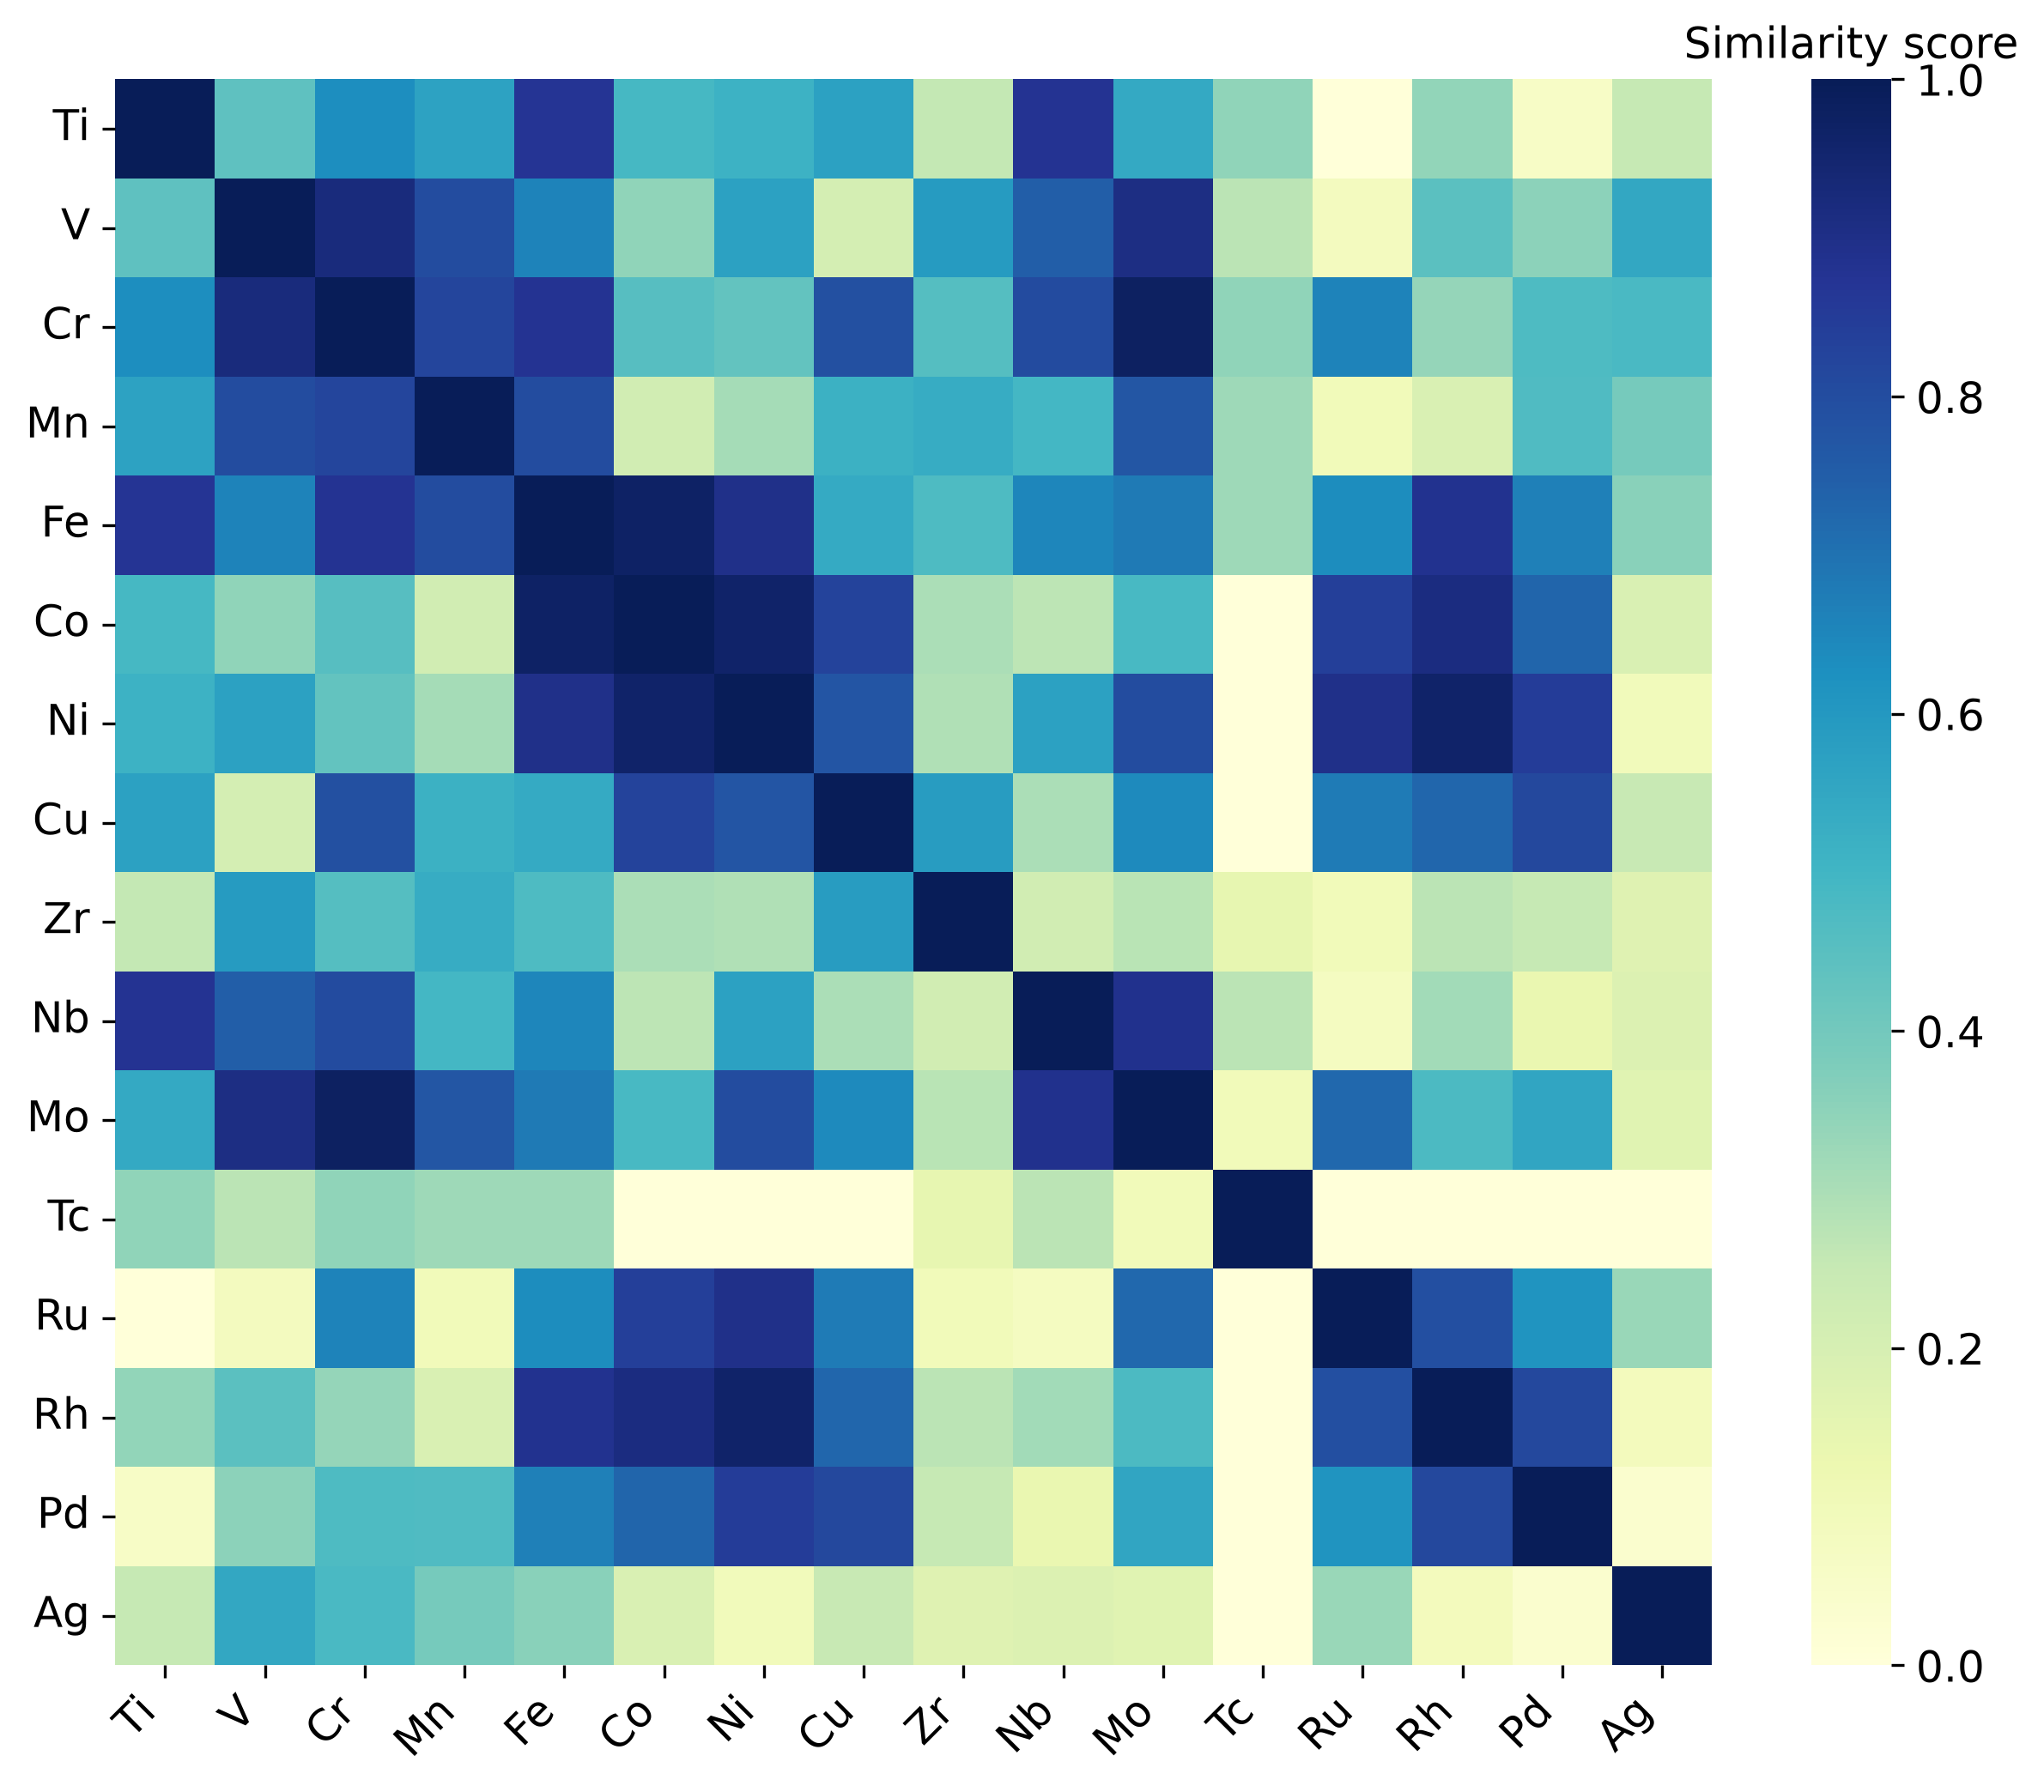

In [8]:
from ERS_misc import plot_similarity_matrix
plot_similarity_matrix(df_similarity, ELEMENTS)


In [9]:
SCALE = .1


In [10]:
from ERS_misc import extract_HEA_evidence


In [11]:
df_similarity

,,Ti,V,Cr,Mn,Fe,Co,Ni,Cu,Zr,...,Ru|Tc,Rh|Tc,Pd|Tc,Ag|Tc,Rh|Ru,Pd|Ru,Ag|Ru,Pd|Rh,Ag|Rh,Ag|Pd
,1.000000,0.772241,0.757401,0.975527,0.983751,0.900591,0.601309,0.792210,0.794337,0.667691,...,0.0,0.0,0.0,0.0,0.359689,0.558117,0.430612,0.128948,0.703847,0.665628
Ti,0.772241,1.000000,0.437704,0.631663,0.568643,0.873808,0.490967,0.514075,0.573530,0.255004,...,0.0,0.0,0.0,0.0,0.000000,0.082569,0.190000,0.196077,0.090909,0.090909
V,0.757401,0.437704,1.000000,0.925205,0.804575,0.658000,0.345366,0.573530,0.208670,0.592038,...,0.0,0.0,0.0,0.0,0.159664,0.417128,0.359689,0.319060,0.255897,0.249082
Cr,0.975527,0.631663,0.925205,1.000000,0.823042,0.878827,0.453158,0.433400,0.790240,0.458625,...,0.0,0.0,0.0,0.0,0.000000,0.417128,0.335799,0.249082,0.236356,0.297052
Mn,0.983751,0.568643,0.804575,0.823042,1.000000,0.802271,0.217869,0.308710,0.516393,0.531997,...,0.0,0.0,0.0,0.0,0.000000,0.168793,0.442434,0.154522,0.442434,0.387560
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Pd|Ru,0.558117,0.082569,0.417128,0.417128,0.168793,0.627029,0.561548,0.752114,0.482848,0.100000,...,0.0,0.0,0.0,0.0,0.000000,1.000000,0.000000,0.000000,0.050462,0.000000
Ag|Ru,0.430612,0.190000,0.359689,0.335799,0.442434,0.055757,0.236356,0.114745,0.290534,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
Pd|Rh,0.128948,0.196077,0.319060,0.249082,0.154522,0.391756,0.312720,0.614504,0.319060,0.074931,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
Ag|Rh,0.703847,0.090909,0.255897,0.236356,0.442434,0.179999,0.236356,0.249082,0.366474,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.050462,0.000000,0.000000,1.000000,0.000000


In [12]:
candidates = [
    ["Fe", "Mn", "Co", "Ti"], ["Fe", "Mn", "Co", "Cu"], ["Fe", "Mn", "Co", "V"],
    ["Fe", "Mn", "Co", "Cr"], ["Fe", "Mn", "Co", "Ni"]]


In [13]:
df_data

,combination,Ti,V,Cr,Mn,Fe,Co,Ni,Cu,Zr,Nb,Mo,Tc,Ru,Rh,Pd,Ag,Label,n_element
0,AgFe,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,not_HEA,2
1,AgPd,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,HEA,2
2,CoCu,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,not_HEA,2
3,CoMn,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,not_HEA,2
4,CoNi,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,HEA,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376,MnTiVZr,1,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,not_HEA,4
377,MoNbNiV,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,0,HEA,4
378,MoNbTiZr,1,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,HEA,4
379,MoNiPdRu,0,0,0,0,0,0,1,0,0,0,1,0,1,0,1,0,HEA,4


In [14]:
final_decisions = []
for candidate in candidates:
    final_decision = MassFunction(coreset={"HEA", "not_HEA"})
    for ith, row in df_data.iterrows():
        alloy_k = ELEMENTS[row[ELEMENTS] == 1]
        label_alloy_k = row["Label"]
        evidence = extract_HEA_evidence(frozenset(candidate), 
                                        frozenset(alloy_k))
        if evidence is not None:
            combination_t, combination_v = evidence
            print(alloy_k, combination_t, combination_v)
            
            index_t, index_v = "|".join(sorted(combination_t)),\
                               "|".join(sorted(combination_v))
            similar_score = df_similarity.loc[index_t, index_v]
            mass_function = MassFunction(source=[({label_alloy_k},
                                     similar_score*SCALE)],
                                         coreset={"HEA", "not_HEA"})
            final_decision = final_decision.combine(mass_function)
    final_decisions.append(final_decision)


['Mn' 'Co'] frozenset() frozenset({'Fe', 'Ti'})
['Mn' 'Fe'] frozenset() frozenset({'Co', 'Ti'})
['Cr' 'Mn' 'Co'] frozenset({np.str_('Cr')}) frozenset({'Fe', 'Ti'})
['Mn' 'Co' 'Cu'] frozenset({np.str_('Cu')}) frozenset({'Fe', 'Ti'})
['Mn' 'Co' 'Rh'] frozenset({np.str_('Rh')}) frozenset({'Fe', 'Ti'})
['Ti' 'Cr' 'Mn'] frozenset({np.str_('Cr')}) frozenset({'Co', 'Fe'})
['Mn' 'Fe' 'Cu'] frozenset({np.str_('Cu')}) frozenset({'Co', 'Ti'})
['Mn' 'Fe' 'Nb'] frozenset({np.str_('Nb')}) frozenset({'Co', 'Ti'})
['Mn' 'Fe' 'Rh'] frozenset({np.str_('Rh')}) frozenset({'Co', 'Ti'})
['Ti' 'Mn' 'Fe'] frozenset() frozenset({'Co'})
['Mn' 'Co' 'Ni'] frozenset({np.str_('Ni')}) frozenset({'Fe', 'Ti'})
['Cr' 'Mn' 'Fe'] frozenset({np.str_('Cr')}) frozenset({'Co', 'Ti'})
['Ti' 'Cr' 'Fe'] frozenset({np.str_('Cr')}) frozenset({'Mn', 'Co'})
['Mn' 'Fe' 'Mo'] frozenset({np.str_('Mo')}) frozenset({'Co', 'Ti'})
['Mn' 'Fe' 'Ni'] frozenset({np.str_('Ni')}) frozenset({'Co', 'Ti'})
['V' 'Mn' 'Fe'] frozenset({np.str_('V')})

['Mn' 'Fe' 'Mo'] frozenset({np.str_('Mo')}) frozenset({'V', 'Co'})
['Mn' 'Fe' 'Ni'] frozenset({np.str_('Ni')}) frozenset({'V', 'Co'})
['V' 'Mn' 'Fe'] frozenset() frozenset({'Co'})
['Ti' 'V' 'Fe'] frozenset({np.str_('Ti')}) frozenset({'Mn', 'Co'})
['Ti' 'V' 'Mn'] frozenset({np.str_('Ti')}) frozenset({'Co', 'Fe'})
['Cr' 'Mn' 'Co' 'Ni'] frozenset({np.str_('Cr'), np.str_('Ni')}) frozenset({'V', 'Fe'})
['Cr' 'Mn' 'Fe' 'Mo'] frozenset({np.str_('Mo'), np.str_('Cr')}) frozenset({'V', 'Co'})
['V' 'Cr' 'Mn' 'Fe'] frozenset({np.str_('Cr')}) frozenset({'Co'})
['V' 'Cr' 'Fe' 'Nb'] frozenset({np.str_('Cr'), np.str_('Nb')}) frozenset({'Mn', 'Co'})
['V' 'Cr' 'Mn' 'Nb'] frozenset({np.str_('Cr'), np.str_('Nb')}) frozenset({'Co', 'Fe'})
['Mn' 'Fe' 'Cu' 'Nb'] frozenset({np.str_('Cu'), np.str_('Nb')}) frozenset({'V', 'Co'})
['V' 'Mn' 'Fe' 'Cu'] frozenset({np.str_('Cu')}) frozenset({'Co'})
['V' 'Mn' 'Cu' 'Mo'] frozenset({np.str_('Mo'), np.str_('Cu')}) frozenset({'Co', 'Fe'})
['V' 'Mn' 'Cu' 'Nb'] frozenset({

['Co' 'Ni' 'Pd' 'Ag'] frozenset({np.str_('Pd'), np.str_('Ag')}) frozenset({'Mn', 'Fe'})
['Fe' 'Ni' 'Pd' 'Ag'] frozenset({np.str_('Pd'), np.str_('Ag')}) frozenset({'Mn', 'Co'})
['Fe' 'Ni' 'Ru' 'Ag'] frozenset({np.str_('Ru'), np.str_('Ag')}) frozenset({'Mn', 'Co'})
['Cr' 'Mn' 'Co' 'Nb'] frozenset({np.str_('Cr'), np.str_('Nb')}) frozenset({'Fe', 'Ni'})
['Co' 'Ni' 'Mo' 'Pd'] frozenset({np.str_('Mo'), np.str_('Pd')}) frozenset({'Mn', 'Fe'})
['Co' 'Ni' 'Rh' 'Pd'] frozenset({np.str_('Pd'), np.str_('Rh')}) frozenset({'Mn', 'Fe'})
['Cr' 'Mn' 'Fe' 'Cu'] frozenset({np.str_('Cr'), np.str_('Cu')}) frozenset({'Co', 'Ni'})
['Cr' 'Fe' 'Ni' 'Cu'] frozenset({np.str_('Cr'), np.str_('Cu')}) frozenset({'Mn', 'Co'})
['Cr' 'Mn' 'Fe' 'Ni'] frozenset({np.str_('Cr')}) frozenset({'Co'})
['Ti' 'Cr' 'Mn' 'Fe'] frozenset({np.str_('Cr'), np.str_('Ti')}) frozenset({'Co', 'Ni'})
['Cr' 'Fe' 'Ni' 'Pd'] frozenset({np.str_('Cr'), np.str_('Pd')}) frozenset({'Mn', 'Co'})
['Cr' 'Mn' 'Ni' 'Nb'] frozenset({np.str_('Cr'), np.st

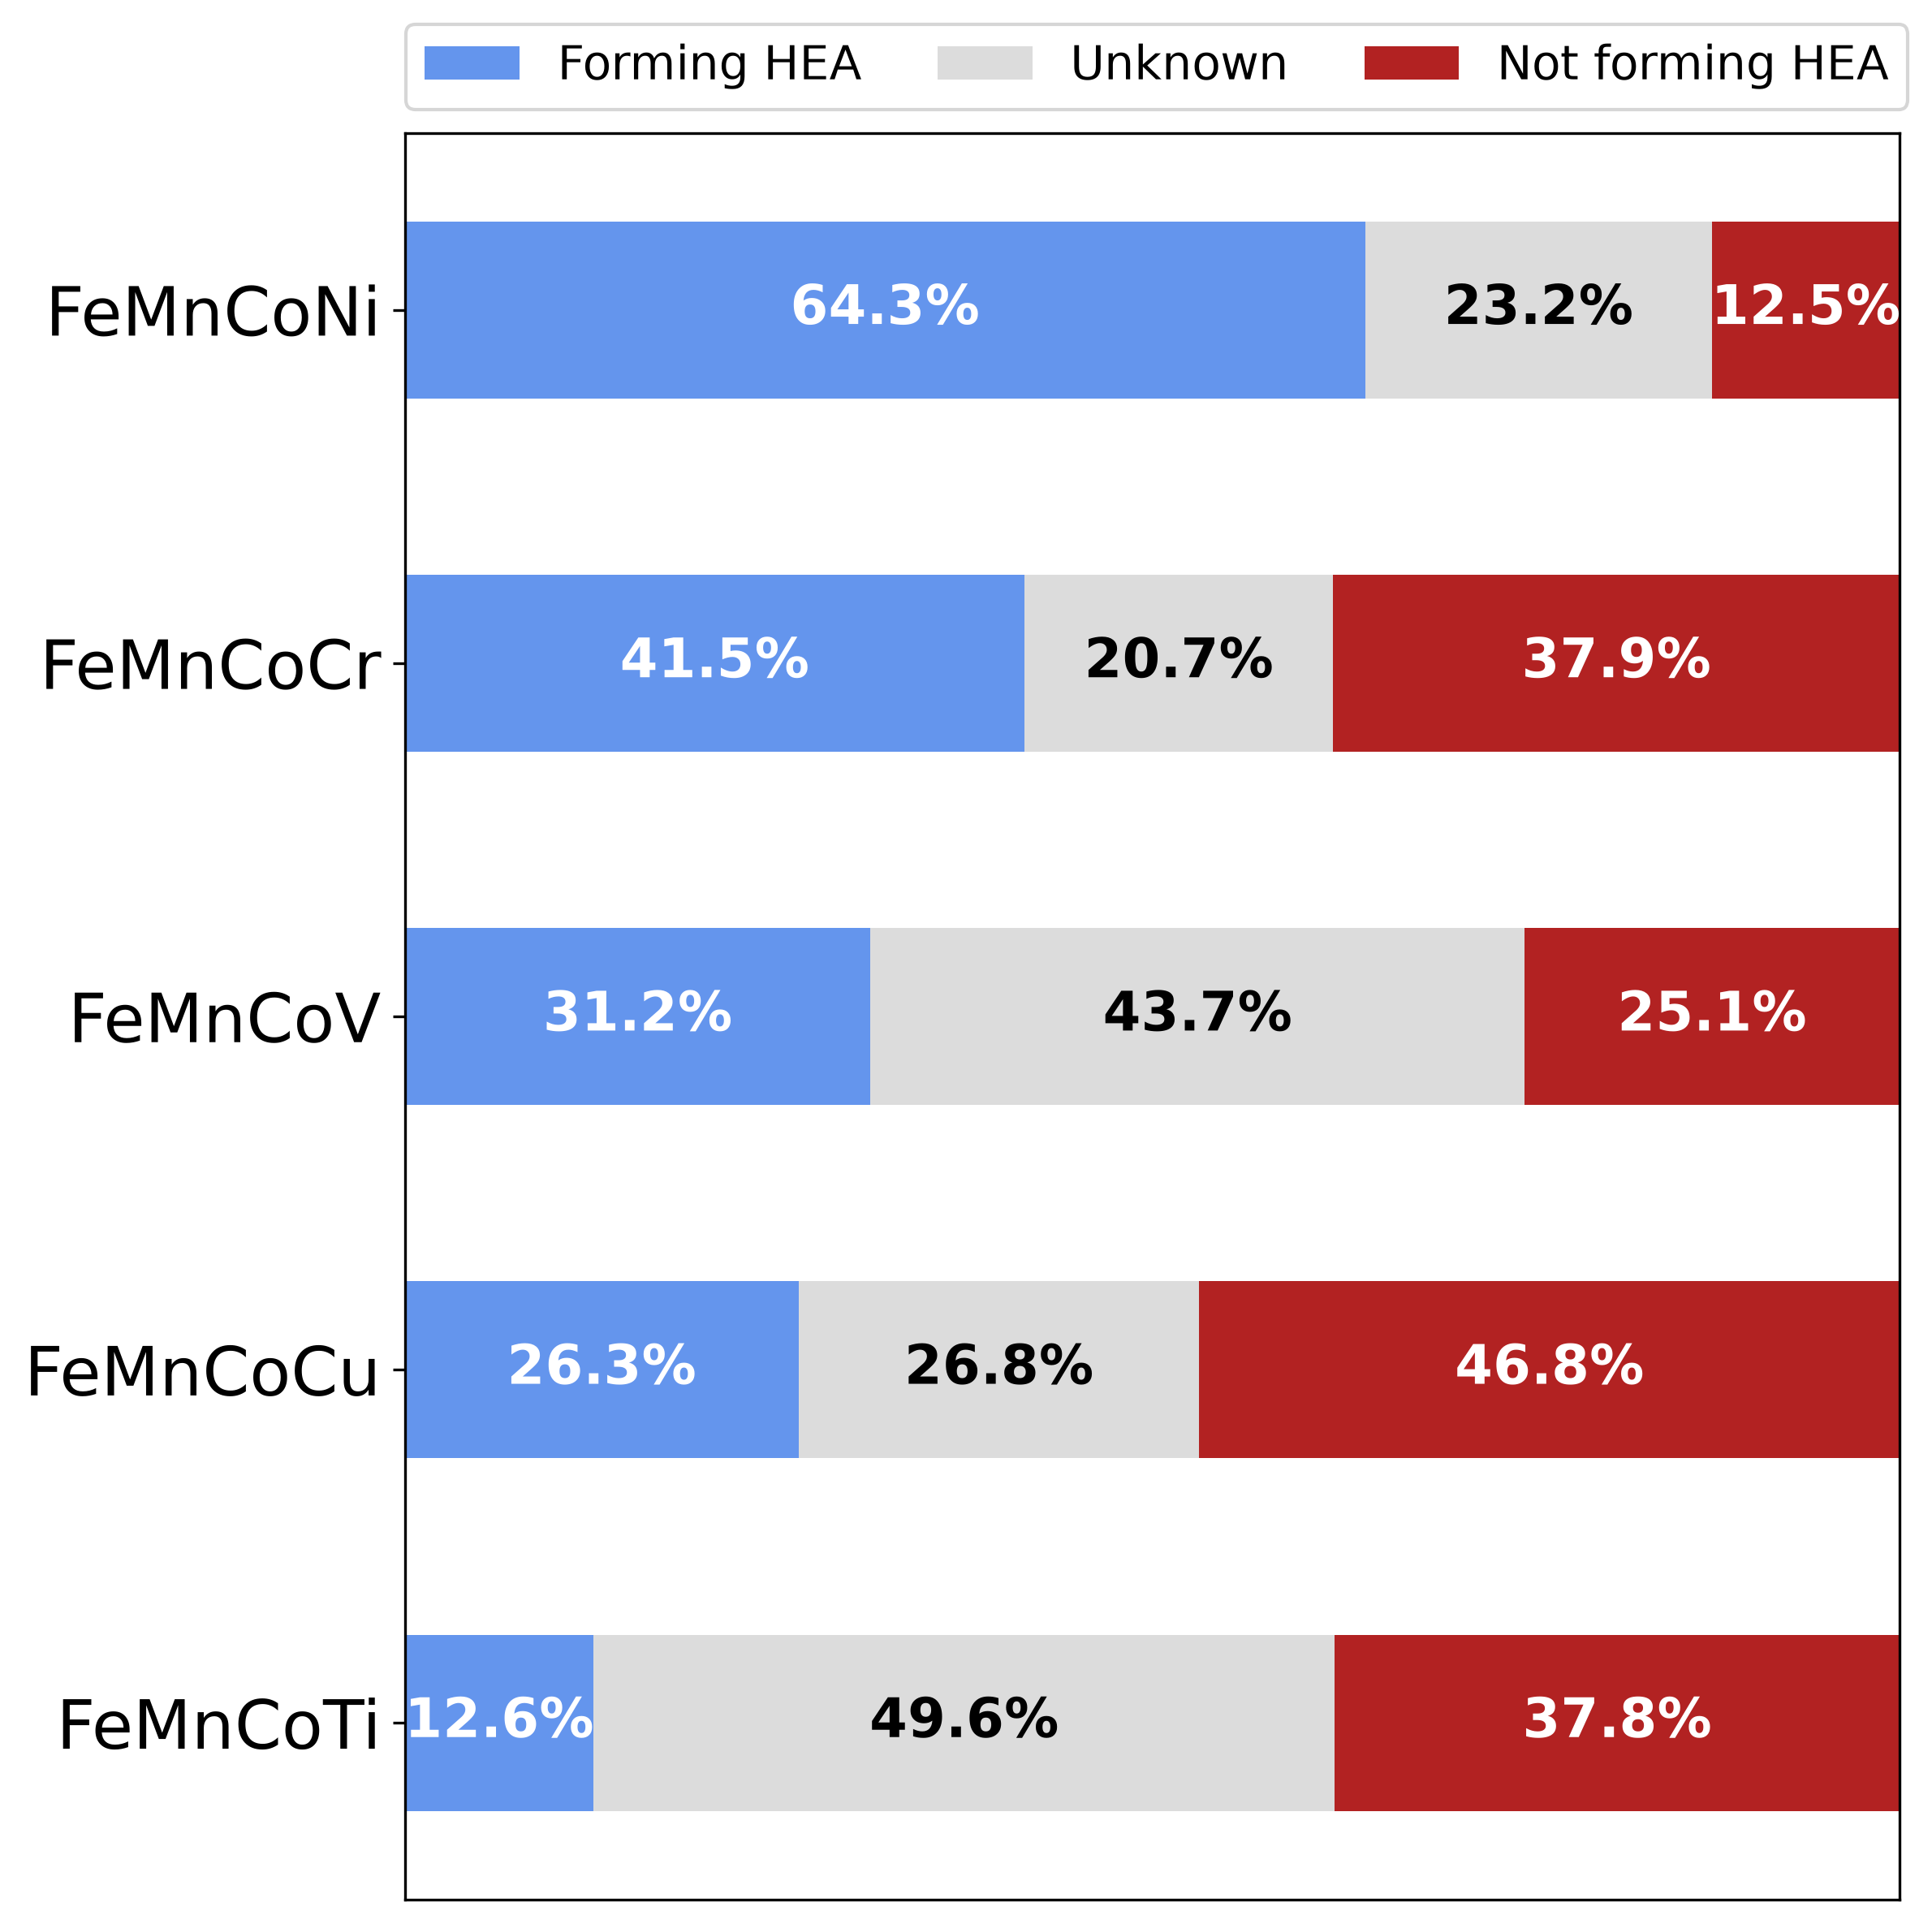

In [15]:
from ERS_misc import plot_final_decisions
import os
import matplotlib.pyplot as plt
plot_final_decisions(candidates, final_decisions)
plt.tight_layout()
os.makedirs("image_executed", exist_ok=True)
plt.savefig("image_executed/HEA4_similarity.png")

上が論文で表示した図です。